## DBSCAN Clustering & PCA
### Mall Customer Segmentation Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE unsupervised model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
Exercises 1-2 in this group project (K-Means, DBSCAN) use:
- the **same dataset**
- the **same cleaning/scaling steps**
- the **same feature set** (`Age`, `Annual Income (k$)`, `Spending Score (1-100)`)
- a **fixed `random_state=42`** everywhere reproducibility matters

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling.
> Important Note: Do not change the preprocessing steps described below, even if you think another approach would work better -> consistency across the group matters more here than optimizing your individual score.

> **Why no train/test split here?** Clustering is unsupervised -> there is no label to predict, so we fit on the **full, scaled dataset** instead of splitting into train/test, exactly as in Exercise 1 (K-Means).

---


## 1. Dataset

**File:** [`Mall_Customers.csv`](https://www.kaggle.com/datasets/shwetabh123/mall-customers)
**Columns:**

| Column | Meaning |
|---|---|
| CustomerID | Unique customer identifier |
| Gender | Male / Female |
| Age | Customer age in years |
| Annual Income (k\$) | Annual income in thousands of dollars |
| Spending Score (1-100) | Score assigned by the mall based on customer behavior and spending |

Place `Mall_Customers.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical to Exercise 1)

Follow these steps **in order**. Do not skip or reorder any step. These are the **same steps as Exercise 1 (K-Means)** so the two exercises are directly comparable.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Drop `CustomerID`** -> it is an identifier, not a feature.
3. **Check for missing values** and duplicated rows; report counts.
4. **Select the clustering features:** `Age`, `Annual Income (k$)`, `Spending Score (1-100)`. `Gender` is **not** used as a clustering feature (kept aside only for optional interpretation in Section 7).
5. **Scale the features** with `StandardScaler`, fit on the **full** feature set. Save the scaled array as `X_scaled`. DBSCAN is distance-based (like KNN), so unscaled features would distort the neighborhood calculations.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import seaborn as sns

URL = r'C:\Users\DELL\Machine learning and stats\Statistics-and-Machine-Learning-1\Week-4\Lab-Assignments\Mall_Customers.csv'
df = pd.read_csv(URL)

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('head',df.head())
print('info',df.info())
print('Describe',df.describe())

drop_columns = ['CustomerID']
df.drop(columns=drop_columns, inplace=True)

missing_values = df.isna().sum()
print('\nMissing values:')
print(missing_values)

duplicated_rows_count = df.duplicated().sum()
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]
print(f'\nSelected features for clustering: {features}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Dataset loaded: 200 rows x 5 columns
Shape: (200, 5)

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object
head    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age    

## 3. Preprocessing & Reproducibility Setup (required -> identical to Exercise 1)

Same as Exercise 1: no `train_test_split` is used. DBSCAN is fit on the entire scaled dataset (`X_scaled`).

- `DBSCAN` itself has no `random_state` parameter (it is deterministic given `eps` and `min_samples`), but keep `random_state=42` on any other component you use (e.g. if you sample data for a plot).
- Print the shape of `X_scaled` to confirm you have all 200 customers and 3 features going into the model.

**Do not change this setup.** It must match Exercise 1 so your final comparison is fair.


In [5]:
print(f'Shape of X_scaled: {X_scaled.shape}')

Shape of X_scaled: (200, 3)


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.preprocessing (StandardScaler)
sklearn.cluster (DBSCAN)
sklearn.neighbors (NearestNeighbors)
sklearn.decomposition (PCA)
sklearn.metrics (silhouette_score, davies_bouldin_score)
```


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_score, davies_bouldin_score

## 5. Training & Hyperparameters

1. **k-distance plot (to help choose `eps`):** using `NearestNeighbors(n_neighbors=5)`, compute the distance from every point to its 5th nearest neighbor, sort these distances, and plot them. The "elbow" in this plot is a good candidate for `eps`.
2. **Try at least 3 values of `eps`** (e.g., 0.3, 0.5, 0.8) with `min_samples` fixed (e.g., 5). For each, report: the number of clusters found (excluding noise) and the number/percentage of points labeled as noise (`label == -1`).
3. **Select your final `eps`/`min_samples`** combination based on step 2 and keep it as your final DBSCAN model.

> **Quick Recap:** This connects to the "DBSCAN: Density-Based Clustering" idea from lecture -> DBSCAN groups points that are close together in dense regions and labels isolated points as noise/outliers, without needing to pre-specify the number of clusters K.


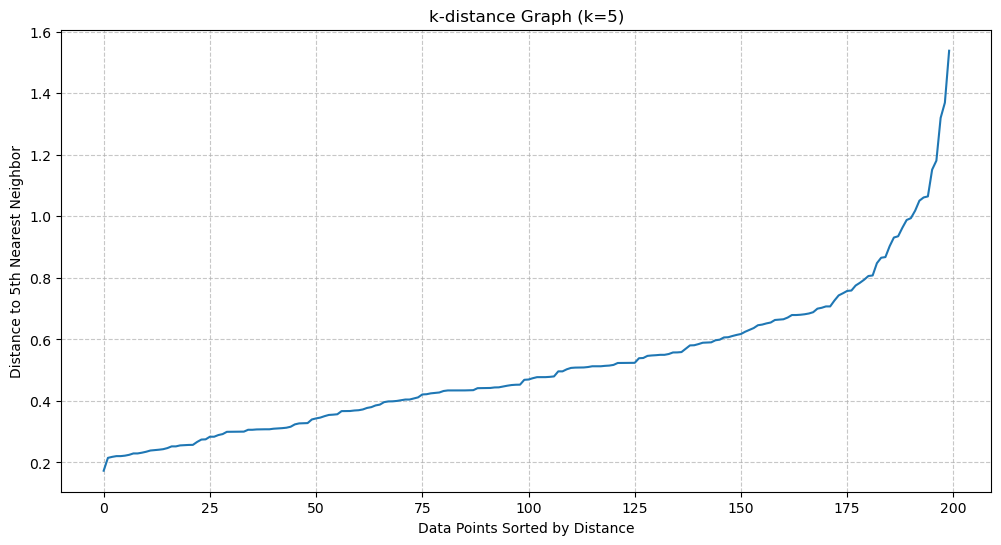

In [15]:
n_neighbors = 5 
neigh = NearestNeighbors(n_neighbors=n_neighbors)
neigh.fit(X_scaled)
distances, indices = neigh.kneighbors(X_scaled)
k_distances = np.sort(distances[:, n_neighbors-1], axis=0)
plt.figure(figsize=(12, 6))
plt.plot(k_distances)
plt.title(f'k-distance Graph (k={n_neighbors})')
plt.xlabel('Data Points Sorted by Distance')
plt.ylabel(f'Distance to {n_neighbors}th Nearest Neighbor')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [18]:
def run_dbscan(eps, min_samples=5):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    sil = np.nan
    if n_clusters > 1:
        mask = labels != -1
        if mask.sum() > 1 and len(np.unique(labels[mask])) > 1:
            sil = silhouette_score(X_scaled[mask], labels[mask])
    return labels, n_clusters, n_noise, sil

eps_values = [0.3, 0.5, 0.8]
db_rows = []
for eps in eps_values:
    labels, n_cl, n_noise, sil = run_dbscan(eps)
    db_rows.append({'eps': eps, 'clusters': n_cl, 'noise_points': n_noise, 'silhouette': sil})
dbscan_summary = pd.DataFrame(db_rows)
display(dbscan_summary.round(3))

,eps,clusters,noise_points,silhouette
0,0.3,10,134,0.514
1,0.5,6,60,0.482
2,0.8,1,6,NaN


In [19]:
final_eps = 0.5
final_min_samples = 5
dbscan_final = DBSCAN(eps=final_eps, min_samples=final_min_samples)
final_clusters = dbscan_final.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = final_clusters

## 6. Evaluation & Visualization

**Required metrics** (compute for your final DBSCAN model):
- Number of clusters found (excluding noise)
- Percentage of points labeled as noise
- Silhouette Score (computed on non-noise points only)
- Davies-Bouldin Index (computed on non-noise points only)

Present these in a small summary table, and note clearly that Silhouette/Davies-Bouldin exclude noise points (unlike K-Means, where every point belongs to a cluster).

**Required visualizations** (3 total):
1. **k-distance plot**, with your chosen `eps` marked as a horizontal or vertical reference line.
2. **PCA cluster scatter plot** -> reduce `X_scaled` to 2 dimensions with PCA and plot the customers colored by their final DBSCAN label, using a distinct color/marker (e.g., gray "x") for noise points.
3. **Cluster size bar chart** -> bar chart of how many customers fall into each cluster, including a separate bar for noise.


In [30]:

import pandas as pd

final_dbscan_labels = df['DBSCAN_Cluster'].values
n_clusters_final = len(set(final_dbscan_labels)) - (1 if -1 in final_dbscan_labels else 0)

n_noise_final = list(final_dbscan_labels).count(-1)
noise_percentage_final = (n_noise_final / len(X_scaled)) * 100

non_noise_indices_final = final_dbscan_labels != -1
X_non_noise = X_scaled[non_noise_indices_final]
labels_non_noise = final_dbscan_labels[non_noise_indices_final]

silhouette_final = np.nan 
davies_bouldin_final = np.nan 

if n_clusters_final > 1 and len(X_non_noise) > 1: 
    silhouette_final = silhouette_score(X_non_noise, labels_non_noise)
    davies_bouldin_final = davies_bouldin_score(X_non_noise, labels_non_noise)
elif n_clusters_final == 1 and len(X_non_noise) > 1: 
    silhouette_final = 0 
    davies_bouldin_final = 1 


metrics_summary = pd.DataFrame({
    'Metric': ['Number of Clusters (excluding noise)', 'Noise Points Percentage','Silhouette Score (on non-noise points)','Davies-Bouldin Index (on non-noise points)'],
    'Value': [ n_clusters_final,f'{noise_percentage_final:.2f}%',f'{silhouette_final:.3f}' if not np.isnan(silhouette_final) else 'N/A',f'{davies_bouldin_final:.3f}' if not np.isnan(davies_bouldin_final) else 'N/A']
})

print(f"Evaluation Metrics for DBSCAN with eps={final_eps}, min_samples={final_min_samples}:")
display(metrics_summary)

Evaluation Metrics for DBSCAN with eps=0.5, min_samples=5:


,Metric,Value
0,Number of Clusters (excluding noise),6
1,Noise Points Percentage,30.00%
2,Silhouette Score (on non-noise points),0.482
3,Davies-Bouldin Index (on non-noise points),0.639


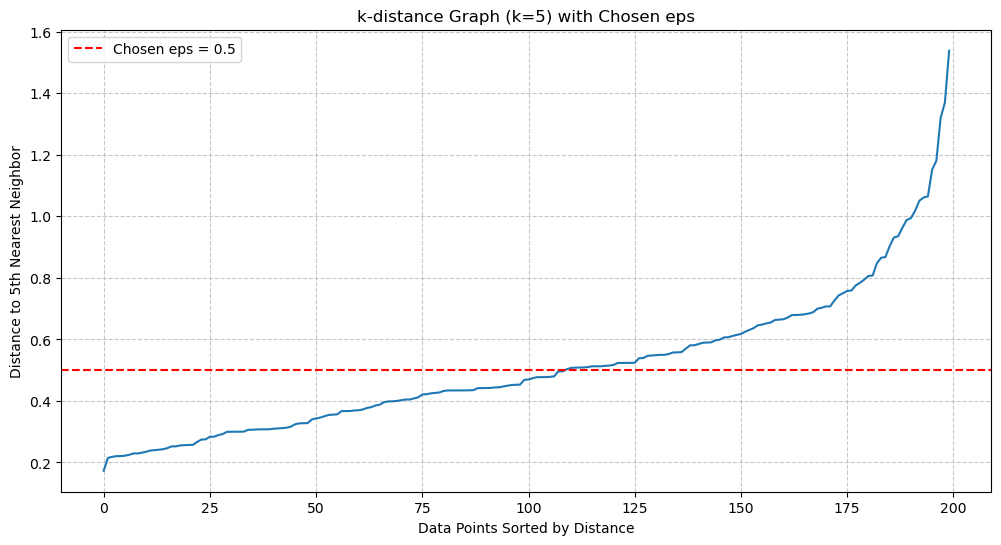

In [29]:

n_neighbors = 5
neigh = NearestNeighbors(n_neighbors=n_neighbors)
neigh.fit(X_scaled)
distances, indices = neigh.kneighbors(X_scaled)
k_distances = np.sort(distances[:, n_neighbors-1], axis=0)

plt.figure(figsize=(12, 6))
plt.plot(k_distances)
plt.axhline(y=final_eps, color='r', linestyle='--', label=f'Chosen eps = {final_eps}')
plt.title(f'k-distance Graph (k={n_neighbors}) with Chosen eps')
plt.xlabel('Data Points Sorted by Distance')
plt.ylabel(f'Distance to {n_neighbors}th Nearest Neighbor')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11876\1238622827.py:12: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(noise_points_pca['PCA1'],noise_points_pca['PCA2'],color='gray',marker='x', s=150, label='Noise (-1)',edgecolor='black')


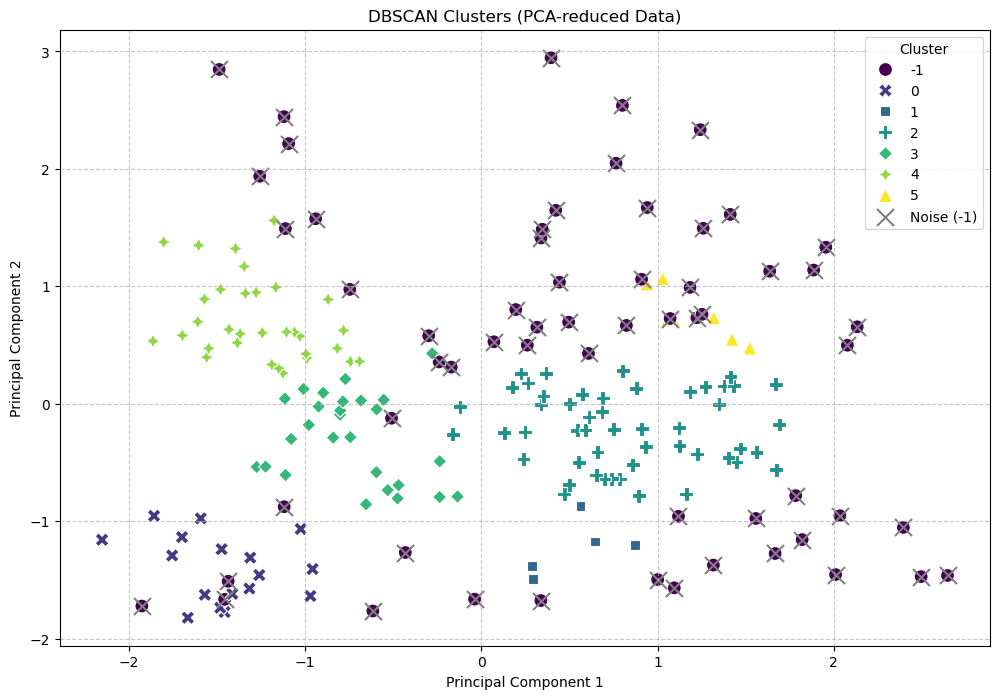

In [26]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(data=X_pca, columns=['PCA1', 'PCA2'])
pca_df['Cluster'] = df['DBSCAN_Cluster'] 

plt.figure(figsize=(12, 8))
sns.scatterplot(x='PCA1',y='PCA2',hue='Cluster',palette='viridis' if pca_df['Cluster'].nunique() > 1 else ['grey'],style='Cluster', markers=True,s=100,data=pca_df,legend='full')

noise_points_pca = pca_df[pca_df['Cluster'] == -1]
if not noise_points_pca.empty:
    plt.scatter(noise_points_pca['PCA1'],noise_points_pca['PCA2'],color='gray',marker='x', s=150, label='Noise (-1)',edgecolor='black')

plt.title('DBSCAN Clusters (PCA-reduced Data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11876\499327301.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')


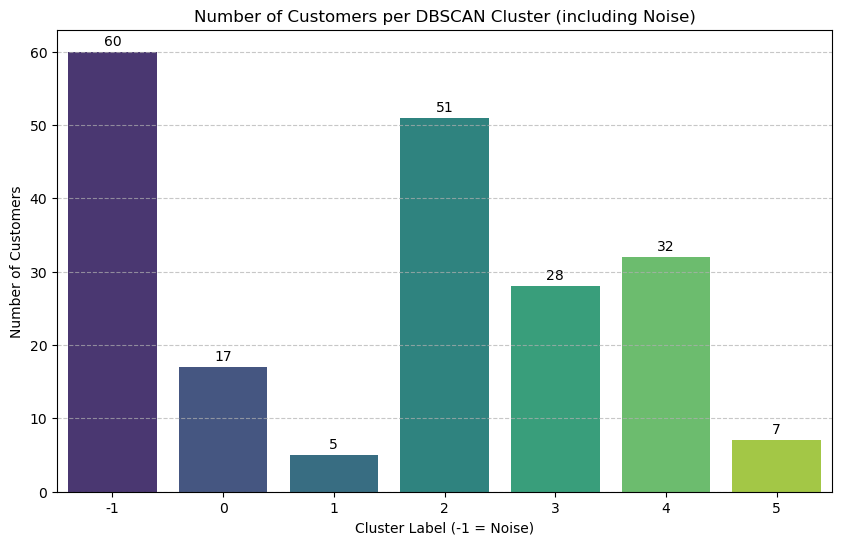

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_counts = df['DBSCAN_Cluster'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')
plt.title('Number of Customers per DBSCAN Cluster (including Noise)')
plt.xlabel('Cluster Label (-1 = Noise)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, value in enumerate(cluster_counts.values):
    plt.text(index, value + 0.5, str(value), ha='center', va='bottom')

plt.show()

## 7. Reflection Questions (write short answers, 1-2 sentences each)

1. Which `eps`/`min_samples` combination did you choose, and how did the k-distance plot help you decide?
2. How many points were labeled as noise, and does that seem reasonable for this dataset, or too high/low?
3. If you had to explain DBSCAN to someone who has never studied ML, what is the one-sentence idea behind it?
4. Compare your DBSCAN clusters to your own K-Means clusters (Exercise 1, if you did it) or to a groupmate's -> did DBSCAN find a similar number of groups? Did it group the same customers together?
5. For this particular dataset, do you think DBSCAN or K-Means produced more meaningful/interpretable clusters, and why?

Answer
1. The eps/min_samples combinations i choose was eps=0.5 min_samples=5,The k-distance plot helped me as i saw an elbow curve around 0.4 - 0.6 ,and also from the summary as 0.5 we get 5 clusters and 60 noise points as this is good balance
2. 60 points were labeled as noise , to check whether it is reasoable or not for this dataset it depends upon if the aim is to identify very distinct, dense customer segments, then a higher percentage of noise might be acceptable as these points don't fit into any clear group. However, if the goal is to categorize almost every customer, then 30% might be considered high. This often requires domain expertise to determine the optimal balance.
3. DBSCAN groups together points that are close to each other and labels points that don't belong to any group as noise (outliers).
4. yes dbscan found the similar no of group which is 6 
5. I think DBscan produced more meaninful clusters as it has lowest Davies-Bouldin score and almost similar silhouette

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Preprocessing/reproducibility setup completed (Section 3)
- [ ] Model trained with the required libraries (Section 4)
- [ ] `eps` selection process completed with at least 3 tested values (Section 5)
- [ ] All 4 required metrics reported (Section 6):
   - Number of clusters (excl. noise)
   - % noise points
   - Silhouette Score (excl. noise)
   - Davies-Bouldin Index (excl. noise)
- [ ] All 3 required visualizations (Section 6):
   - k-distance plot
   - PCA cluster scatter plot (with noise highlighted)
   - Cluster size bar chart
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model found the "cleanest" clusters (highest Silhouette, lowest Davies-Bouldin)?
- How does DBSCAN's noise detection change how you'd use this segmentation in practice, compared to K-Means (where every customer is forced into a cluster)?
- Did K-Means and DBSCAN roughly agree on how many meaningful customer groups exist in this data?
- Which method would you recommend to the marketing team, and why?


